# skfolio presentation/demonstration
skfolio is a free Python library for portfolio optimization, factor model construction, and risk management built on top of scikit-learn. It offers a unified interface and tools compatible with scikit-learn to build, fine-tune, cross-validate, and stress-test portfolio models.

I chose it as it is topical for me right now because I am getting back into the field of quantatative finance and this library provides many different portfolio optimizations and weights which could potentially be useful.

Some context: your portfolio is the sum of all your instruments across all asset classes, whether it be shares of AAPL (US Equities) or Japanese Government Bonds. But each person has a limited amount of capital, and so then the game becomes how much of my capital do I allocate to each of my instruments within my portfolio? There are a ton of different ways to do this, with most of the popular ones being inverse risk proportional (the more risky the less capital allocated) and skfolio allows for these portfolio weights to be calculated through various means.

Link: https://github.com/skfolio/skfolio



## 1: Problems Solved
- **Optimization of Portfolio Weights**: Allows for many types of portfolio optimizations (equal weighted, inverse-volatility, diversification maximization, Hierarchical Risk Parity, etc)

- **Distance**: Allows for certain distance estimations (spearman, kendall, pearson, covariance)
    - For example: Pearson can be used to identify correlation between two instruments in order to determine their relative correlation, and from that, you can begin to understand your portfolio's diversification.

- **Covariance methods**: are included with skfolio for a similar reason to the distance calculations, in order to make decisions to reach a certain amount of risk in your portfolio, you need to know the distance and depending on the person they may want to use a more computationally intensive method to calculate this, which is what some of these covariance methods are for

- **Optimization of Various Metrics**: General optimization features like "Minimize Risk", "Maximize Returns", "Turnover Constraints", etc are included, though in my personal opinion those don't have a ton of merit as they can be fun but will likely lead to overfitting.

## 2: Stakeholders
- **Maintainers & contributors**: Open source on GitHub since 2023; ~46 contributors lifetime, 15+ in the past year

- **Users**: Researchers who want sklearn-style portfolio models (optimization, priors, cross-validation, stress tests)

- **How the project works**: Issues and pull requests on GitHub, [CONTRIBUTING.md](https://github.com/skfolio/skfolio/blob/main/CONTRIBUTING.md) (including AI policy), automatic tests and **CI**. BSD license. 

- **What different people want**: Users care about dependable weights and examples that run. mMintainers care about API consistency and green CIs. A risk focused stakeholder cares about stable and interpretable risk estimates.

## 3: Metrics and Features
- **Accuracy** here usually means **statistical quality of inputs** (mean/covariance, factors) and **feasible optimizer solutions**, not “predict the market.”

- **Conditioning**: Sample covariance from returns can be bad when the estimation window is short relative to the number of assets, but this is a fundamental field issue where it was never meant for that to work, it is outside the bounds of realistic utility.

- **Cost**: Some steps are cheap (simple sample covariance), while others are slow (distribution models, big asset lists, convex solvers). “Fast” depends on the picked method and asset count.

- **Modeling for conditioning**: skfolio doesn’t always use one raw sample covariance. It can use priors (a very educated guess on market conditions) so the optimizer can use a more stable (ideally) estimate.

- **Stakeholder success metrics**: A trader will want to know if a portfolio did bad after optimizing it, a numerics person would want to know if a given matrix was hard to invert

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from skfolio.datasets import load_sp500_dataset
from skfolio.preprocessing import prices_to_returns
from skfolio.optimization import MeanRisk
from skfolio.prior import EmpiricalPrior

In [10]:
prices = load_sp500_dataset()
X = prices_to_returns(prices)

model = MeanRisk(prior_estimator=EmpiricalPrior())
model.fit(X)
w = model.weights_

In [11]:
print("=== Prices dataset ===")
print("Shape (days × tickers):", prices.shape)
print("Tickers:", list(prices.columns))
print("\nFirst 5 rows:")
print(prices.head())
print("\nLast 3 rows:")
print(prices.tail(3))

=== Prices dataset ===
Shape (days × tickers): (8313, 20)
Tickers: ['AAPL', 'AMD', 'BAC', 'BBY', 'CVX', 'GE', 'HD', 'JNJ', 'JPM', 'KO', 'LLY', 'MRK', 'MSFT', 'PEP', 'PFE', 'PG', 'RRC', 'UNH', 'WMT', 'XOM']

First 5 rows:
             AAPL    AMD    BAC    BBY    CVX      GE     HD    JNJ    JPM  \
Date                                                                         
1990-01-02  0.264  4.125  4.599  0.144  4.991  14.391  1.117  3.438  3.394   
1990-01-03  0.266  4.000  4.636  0.161  4.910  14.364  1.121  3.452  3.508   
1990-01-04  0.267  3.938  4.537  0.159  4.847  14.283  1.128  3.459  3.522   
1990-01-05  0.268  3.812  4.438  0.159  4.775  14.148  1.113  3.423  3.536   
1990-01-08  0.269  3.812  4.463  0.147  4.820  14.229  1.102  3.481  3.536   

               KO    LLY    MRK   MSFT    PEP    PFE     PG    RRC    UNH  \
Date                                                                        
1990-01-02  2.235  6.658  4.215  0.384  4.738  1.021  3.860  3.322  0.310   
1

In [12]:
print("Sum of weights:", w.sum())
print("Number of weights > 1%:", (w > 0.01).sum())

Sum of weights: 1.0000000000000002
Number of weights > 1%: 12


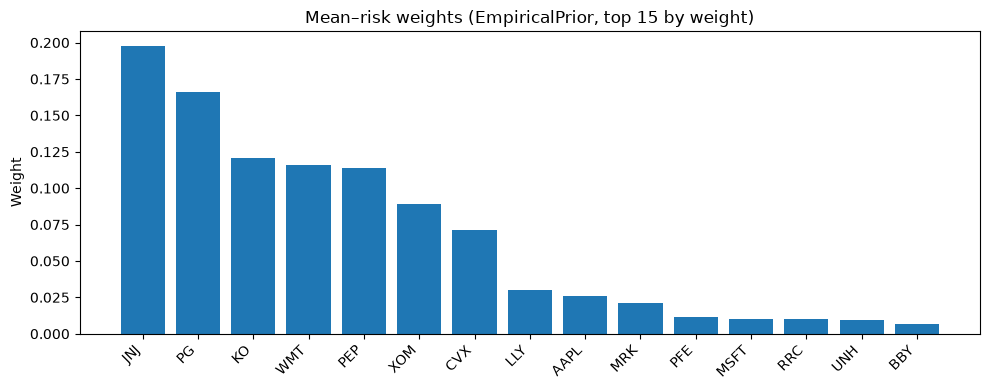

In [16]:
names = np.asarray(model.feature_names_in_)
order = np.argsort(w)[::-1]          # indices: largest weight first
top_n = 15
idx = order[:top_n]
plt.figure(figsize=(10, 4))
plt.bar(names[idx], w[idx])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Weight")
plt.title("Mean–risk weights (EmpiricalPrior, top 15 by weight)")
plt.tight_layout()
plt.show()

In [17]:
import pandas as pd

weights_df = pd.DataFrame({"ticker": names, "weight": w}).sort_values("weight", ascending=False)
print(weights_df.to_string(index=False))

ticker       weight
   JNJ 1.978506e-01
    PG 1.657858e-01
    KO 1.208354e-01
   WMT 1.156923e-01
   PEP 1.136656e-01
   XOM 8.923165e-02
   CVX 7.158606e-02
   LLY 3.004855e-02
  AAPL 2.603599e-02
   MRK 2.105591e-02
   PFE 1.175529e-02
  MSFT 1.000895e-02
   RRC 9.863347e-03
   UNH 9.691815e-03
   BBY 6.891728e-03
    HD 2.852778e-07
    GE 2.701945e-07
   AMD 2.353144e-07
   JPM 1.143364e-07
   BAC 9.347095e-08
